# EDA & ABC/XYZ Analysis

Ноутбук загружает результаты Notebook 01. Все числовые выводы рассчитываются из актуальных данных; заранее написанные неподтверждённые числа удалены.

## Уточнение по словарю данных и бизнес-правилам

В источнике `Sales_Amount` уже является записанной **net sales amount**, а `Profit` — записанной прибылью транзакции. Эти показатели не пересчитываются из цены/скидки или разницы Sales_Amount и Cost_Amount.

`Order_Status` — операционный статус, `Return_Flag` — признак возврата. В проекте используется аналитическое допущение `Completed` + не возвращённая строка как база реализованных продаж. Это не финансовое правило, прямо установленное словарём.

B2B определяется только значением `Sales_Channel == 'B2B Portal'`. Bulk — отдельный флаг объёма строки и не является синонимом B2B.


In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('default')
sns.set_theme(style='whitegrid')

CWD = Path.cwd().resolve()
CANDIDATES = [CWD, *CWD.parents, Path('/mnt/data')]
BASE_DIR = next((p for p in CANDIDATES if (p / 'processed' / 'sales_bi_ready.csv').exists()), CWD)
PROCESSED_DIR = BASE_DIR / 'processed'
EDA_DIR = BASE_DIR / 'eda'
EDA_DIR.mkdir(parents=True, exist_ok=True)
SALES_BI_READY_PATH = PROCESSED_DIR / 'sales_bi_ready.csv'
RFM_BI_READY_PATH = PROCESSED_DIR / 'rfm_bi_ready.csv'

print('Рабочая директория:', BASE_DIR)


Рабочая директория: /Users/caseynger/DE/final_work_fa


In [2]:
# Загрузка и контракт входных данных
assert SALES_BI_READY_PATH.exists(), 'Сначала выполните Notebook 01 (Restart & Run All).'
assert RFM_BI_READY_PATH.exists(), 'Не найден rfm_bi_ready.csv; выполните Notebook 01.'
df = pd.read_csv(SALES_BI_READY_PATH, parse_dates=['order_date','first_realized_purchase'])
rfm = pd.read_csv(RFM_BI_READY_PATH, parse_dates=['first_purchase','last_purchase'])

REQUIRED = {'customer_id','order_id','product_id','product_subcategory','product_category',
            'order_date','quantity','sales_amount','profit','is_realized','net_sales','net_profit',
            'is_b2b_channel','is_bulk_order_line','is_loss'}
missing = REQUIRED - set(df.columns)
assert not missing, f'Отсутствуют обязательные поля: {sorted(missing)}'
assert rfm['customer_id'].is_unique, 'RFM должен содержать одну строку на клиента.'
assert df['is_realized'].isin([0,1]).all()
assert np.allclose(df['net_sales'], df['sales_amount'] * df['is_realized'])

# Order_ID repeats across different customers in the source. The dictionary describes
# it as an order identifier, but observed values are not globally unique; use composite key.
df['customer_order_key'] = (
    df['customer_id'].astype('string') + '|' + df['order_id'].astype('string')
)
assert not df.duplicated(['customer_id','order_id','transaction_id']).any()

print(f'Строк: {len(df):,}; клиентов: {df.customer_id.nunique():,}; SKU: {df.product_id.nunique():,}')
print(f"Период: {df.order_date.min().date()} — {df.order_date.max().date()}")
print('RFM-сегменты:', sorted(rfm['segment'].dropna().unique().tolist()))
print('Статусы заказа:')
print(df['order_status'].value_counts(dropna=False))


Строк: 17,992; клиентов: 4,882; SKU: 28
Период: 2022-01-01 — 2025-12-31
RFM-сегменты: ['At Risk', 'Big Spenders', 'Champions', 'Hibernating', 'Lost VIPs', 'Loyal', 'New', 'Other']
Статусы заказа:
order_status
completed     11531
shipped        2552
returned       1597
processing     1419
cancelled       893
Name: count, dtype: int64


## Этап 1. Общая динамика продаж

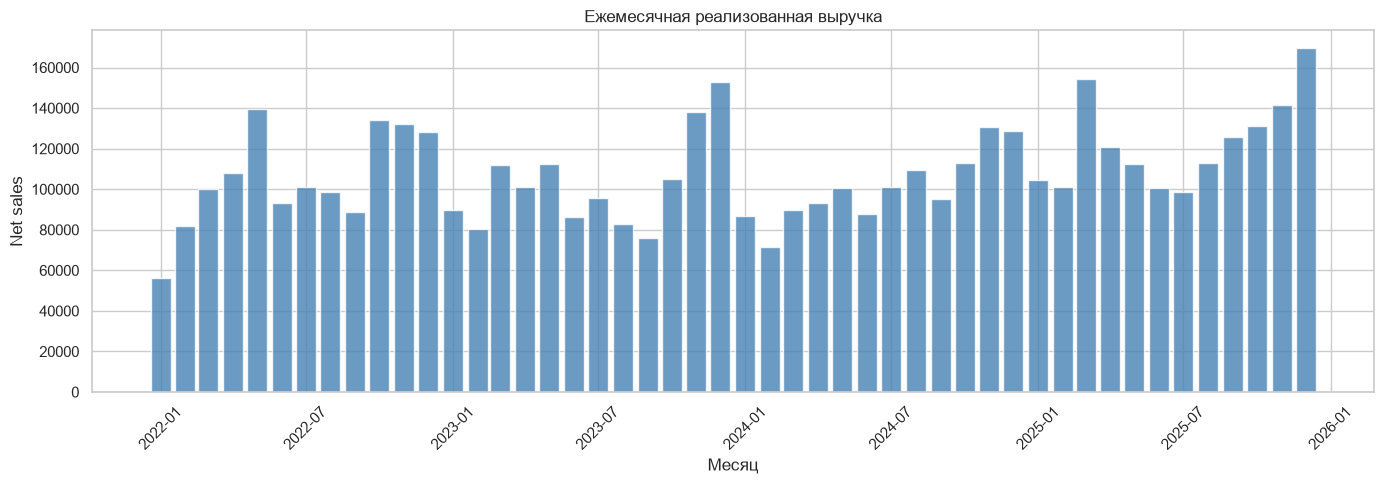

Годовая динамика:
       net_sales  avg_monthly_sales  months
year                                       
2022  1261521.20          105126.77      12
2023  1232384.65          102698.72      12
2024  1207417.73          100618.14      12
2025  1473686.59          122807.22      12


In [3]:
# Месячные показатели: net revenue только по завершённым и не возвращённым продажам.
monthly = (df.groupby(df['order_date'].dt.to_period('M'))
           .agg(net_sales=('net_sales','sum'), net_profit=('net_profit','sum'),
                realized_orders=('customer_order_key', lambda s: s[df.loc[s.index,'is_realized'].eq(1)].nunique()))
           .reset_index().rename(columns={'order_date':'month'}))
monthly['month'] = monthly['month'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14,5))
ax.bar(monthly['month'], monthly['net_sales'], width=25, color='steelblue', alpha=.8)
ax.set(title='Ежемесячная реализованная выручка', xlabel='Месяц', ylabel='Net sales')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

yearly = monthly.assign(year=monthly['month'].dt.year).groupby('year').agg(
    net_sales=('net_sales','sum'), avg_monthly_sales=('net_sales','mean'), months=('month','nunique')
)
print('Годовая динамика:')
print(yearly.round(2).to_string())


### Интерпретация динамики

Сравнивайте годовые суммы и средние месячные значения с учётом неполных лет. Сезонность оценивайте по повторяемости месячного профиля в нескольких годах; один высокий Q4 сам по себе не доказывает устойчивую сезонность.

## Этап 2. Распределение чеков и прибыльности

Composite customer-orders: 17991
Orders with mixed channel (review separately): 1


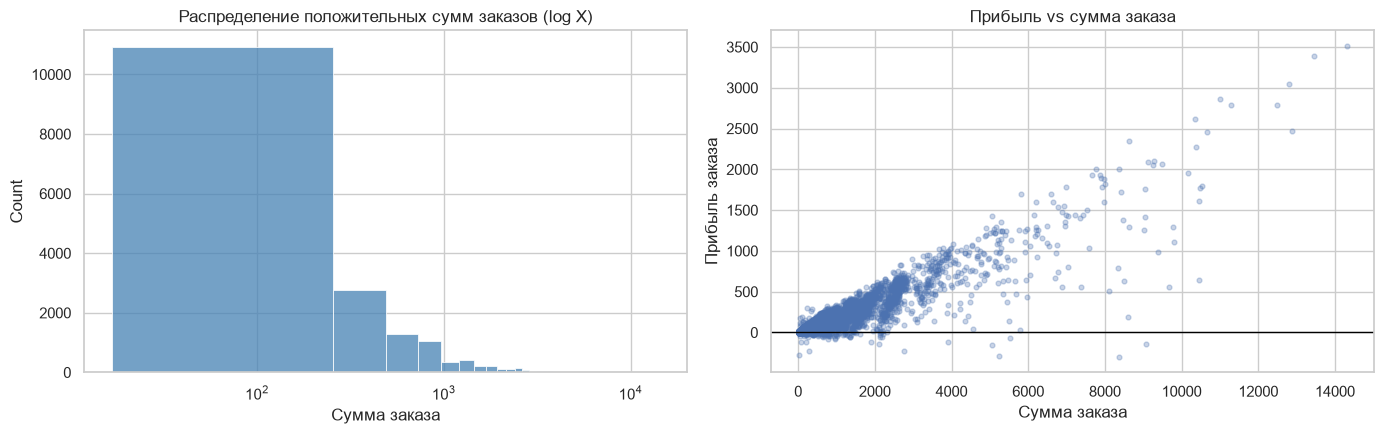

Убыточные строки: 231
Убыточные заказы: 231
Доля убыточных заказов, %: 1.28


In [12]:
# Агрегируем строки до уровня заказа, чтобы средний чек не зависел от числа товарных строк.
order_level = (df.groupby(['customer_id','order_id']).agg(
    sales_amount=('sales_amount','sum'), profit=('profit','sum'),
    net_sales=('net_sales','sum'), net_profit=('net_profit','sum'),
    is_realized=('is_realized','min'),
    sales_channel=('sales_channel', lambda s: s.iloc[0] if s.nunique(dropna=False) == 1 else 'Mixed/Review'),
    is_b2b_channel=('is_b2b_channel','max')
).reset_index())
order_level['customer_order_key'] = (
    order_level['customer_id'].astype('string') + '|' + order_level['order_id'].astype('string')
)
print('Composite customer-orders:', len(order_level))
print('Orders with mixed channel (review separately):', int(order_level['sales_channel'].eq('Mixed/Review').sum()))

fig, axes = plt.subplots(1,2,figsize=(14,4.5))
positive_sales = order_level.loc[order_level['sales_amount'] > 0, 'sales_amount']
sns.histplot(positive_sales, bins=60, ax=axes[0], color='steelblue')
axes[0].set_xscale('log'); axes[0].set_title('Распределение положительных сумм заказов (log X)')
axes[0].set_xlabel('Сумма заказа')
axes[1].scatter(order_level['sales_amount'], order_level['profit'], alpha=.3, s=12)
axes[1].axhline(0,color='black',lw=1)
axes[1].set_xlabel('Сумма заказа'); axes[1].set_ylabel('Прибыль заказа'); axes[1].set_title('Прибыль vs сумма заказа')
plt.tight_layout(); plt.show()

print('Убыточные строки:', int(df['is_loss'].sum()))
print('Убыточные заказы:', int(order_level['profit'].lt(0).sum()))
print('Доля убыточных заказов, %:', round(order_level['profit'].lt(0).mean()*100,2))


## Этап 3. B2B Portal vs остальные каналы

В исходных данных `Sales_Channel = B2B Portal` — прямой признак канала. Другие каналы объединены в `Other channels`, но не называются B2C без подтверждения справочником. Bulk order анализируется отдельно по количеству.

In [13]:
# Сводка по заказам, а не по строкам товара.
channel_summary = (order_level.groupby('sales_channel').agg(
    orders=('customer_order_key','size'), recorded_sales_amount=('sales_amount','sum'),
    net_sales=('net_sales','sum'), net_profit=('net_profit','sum'),
    avg_order_value=('net_sales', lambda s: s[s > 0].mean())
).reset_index())
channel_summary['net_margin'] = channel_summary['net_profit'] / channel_summary['net_sales'].replace(0,np.nan)
channel_summary['revenue_share'] = channel_summary['net_sales'] / channel_summary['net_sales'].sum()
print(channel_summary.sort_values('net_sales',ascending=False).round(4).to_string(index=False))

bulk_summary = (df.groupby('is_bulk_order_line').agg(
    lines=('transaction_id','size'), quantity=('quantity','sum'),
    net_sales=('net_sales','sum'), net_profit=('net_profit','sum')
).reset_index())
bulk_summary['label'] = np.where(bulk_summary['is_bulk_order_line'].eq(1),'Bulk line (qty ≥ 95th pct)','Other lines')
bulk_summary['net_margin'] = bulk_summary['net_profit'] / bulk_summary['net_sales'].replace(0,np.nan)
print('\nBulk quantity diagnostic:')
print(bulk_summary.round(3).to_string(index=False))


sales_channel  orders  recorded_sales_amount  net_sales  net_profit  avg_order_value  net_margin  revenue_share
       Online    8190             3108762.05 1907604.26   388754.98         370.6965      0.2038         0.3686
 Retail Store    6221             2449189.44 1547248.50   307960.81         394.1030      0.1990         0.2990
   B2B Portal    2123             2120749.18 1362770.76   272863.73        1001.3011      0.2002         0.2633
  Phone Order    1456              549836.07  356535.20    70637.75         389.6560      0.1981         0.0689
 Mixed/Review       1                 936.30     851.45      138.70         851.4500      0.1629         0.0002

Bulk quantity diagnostic:
 is_bulk_order_line  lines  quantity  net_sales  net_profit                      label  net_margin
                  0  17067     30696 4147606.32   833991.79                Other lines       0.201
                  1    925      7587 1027403.85   206364.18 Bulk line (qty ≥ 95th pct)       0.201


## Этап 4. ABC-анализ

ABC классифицирует объекты по вкладу в реализованную выручку. Порог A=80%, B=95%, C=остаток. Объекты сортируются по убыванию выручки; пограничный объект относится к группе, в которой он пересекает кумулятивный порог.

In [14]:
def calculate_abc(data, group_col, value_col='net_sales', a_thr=0.80, b_thr=0.95):
    """ABC по положительному вкладу; отрицательные/нулевые итоги не формируют долю продаж."""
    agg = data.groupby(group_col, dropna=False)[value_col].sum().reset_index()
    agg = agg.loc[agg[value_col] > 0].sort_values([value_col,group_col], ascending=[False,True]).reset_index(drop=True)
    total = agg[value_col].sum()
    if total <= 0 or agg.empty:
        agg['share'] = np.nan; agg['cum_share'] = np.nan; agg['ABC_Group'] = 'N/A'
        return agg
    agg['share'] = agg[value_col] / total
    agg['cum_share'] = agg['share'].cumsum()
    # включаем текущий объект в порог: первый объект, пересекающий 80%, относится к A.
    previous_cum = agg['cum_share'].shift(fill_value=0)
    agg['ABC_Group'] = np.select([previous_cum < a_thr, previous_cum < b_thr],['A','B'],default='C')
    return agg

abc_sku = calculate_abc(df,'product_id')
abc_sub = calculate_abc(df,'product_subcategory')
abc_cat = calculate_abc(df,'product_category')

print('ABC по SKU:', abc_sku['ABC_Group'].value_counts().to_dict())
print('ABC по подкатегориям:', abc_sub['ABC_Group'].value_counts().to_dict())
print('ABC по категориям:', abc_cat['ABC_Group'].value_counts().to_dict())


ABC по SKU: {'A': 13, 'B': 10, 'C': 5}
ABC по подкатегориям: {'A': 7, 'B': 6, 'C': 4}
ABC по категориям: {'A': 2, 'B': 2}


## Этап 5. XYZ-анализ

XYZ рассчитывается по месячному количеству реализованных единиц и коэффициенту вариации (CV = σ / μ). Нулевые месяцы внутри наблюдаемого окна учитываются. Поскольку в CSV нет дат заведения/вывода SKU из ассортимента и данных о наличии на складе, окно наблюдения начинается с первой реализованной продажи SKU и продолжается до последнего месяца датасета. Это приближение, а не подтверждённый период доступности товара.

In [15]:
def calculate_xyz(data, group_col, value_col='quantity', x_thr=0.30, y_thr=0.40, min_periods=6):
    realized = data.loc[data['is_realized'].eq(1) & data[value_col].notna()].copy()
    if realized.empty:
        return pd.DataFrame(columns=[group_col,'mean','std','cv','total','n_periods','active_periods','XYZ_Group'])
    realized['month'] = realized['order_date'].dt.to_period('M')
    monthly = realized.groupby([group_col,'month'])[value_col].sum().reset_index()
    global_end = realized['month'].max()
    rows=[]
    for key, part in monthly.groupby(group_col, dropna=False):
        start = part['month'].min()
        idx = pd.period_range(start, global_end, freq='M')
        series = part.set_index('month')[value_col].reindex(idx, fill_value=0).astype(float)
        mean = series.mean()
        std = series.std(ddof=0)  # population CV for the observed period
        cv = std / mean if mean > 0 else np.nan
        n = len(series)
        if n < min_periods or mean == 0:
            group = 'N'
        elif cv <= x_thr:
            group = 'X'
        elif cv <= y_thr:
            group = 'Y'
        else:
            group = 'Z'
        rows.append({group_col:key,'mean':mean,'std':std,'cv':cv,'total':series.sum(),
                     'n_periods':n,'active_periods':int((series>0).sum()),'XYZ_Group':group,
                     'observation_start':str(start),'observation_end':str(global_end)})
    return pd.DataFrame(rows)

xyz_sku = calculate_xyz(df,'product_id')
xyz_sub = calculate_xyz(df,'product_subcategory')
xyz_cat = calculate_xyz(df,'product_category')

product_attrs = (df.sort_values('product_name').groupby('product_id',as_index=False)
                 .agg(product_name=('product_name','first'),product_category=('product_category','first'),
                      product_subcategory=('product_subcategory','first')))
abc_xyz_sku = abc_sku.merge(xyz_sku,on='product_id',how='outer',validate='1:1').merge(product_attrs,on='product_id',how='left',validate='1:1')
abc_xyz_sub = abc_sub.merge(xyz_sub,on='product_subcategory',how='outer',validate='1:1')
abc_xyz_cat = abc_cat.merge(xyz_cat,on='product_category',how='outer',validate='1:1')
for frame in [abc_xyz_sku,abc_xyz_sub,abc_xyz_cat]:
    frame['ABC_Group'] = frame['ABC_Group'].fillna('N/A')
    frame['XYZ_Group'] = frame['XYZ_Group'].fillna('N')
    frame['ABC_XYZ_Matrix'] = frame['ABC_Group'] + frame['XYZ_Group']

print('SKU matrix:'); print(abc_xyz_sku['ABC_XYZ_Matrix'].value_counts().sort_index().to_string())
print('\nSubcategory matrix:'); print(abc_xyz_sub['ABC_XYZ_Matrix'].value_counts().sort_index().to_string())


SKU matrix:
ABC_XYZ_Matrix
AZ    13
BY     2
BZ     8
CY     1
CZ     4

Subcategory matrix:
ABC_XYZ_Matrix
AX    1
AY    2
AZ    4
BY    1
BZ    5
CY    1
CZ    3


## Этап 6. Матрицы ABC/XYZ и визуализация

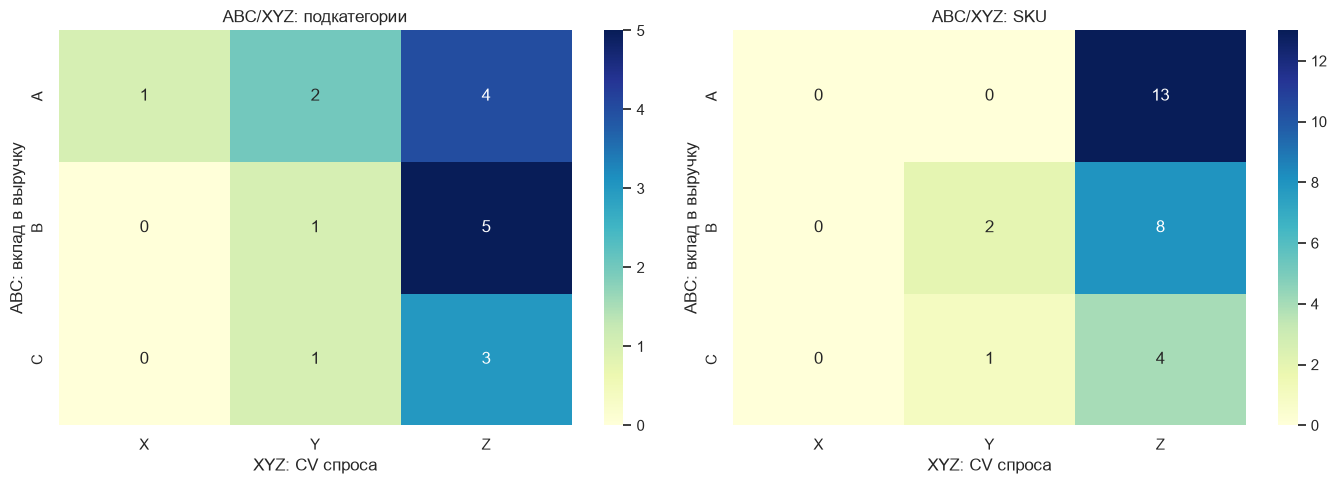

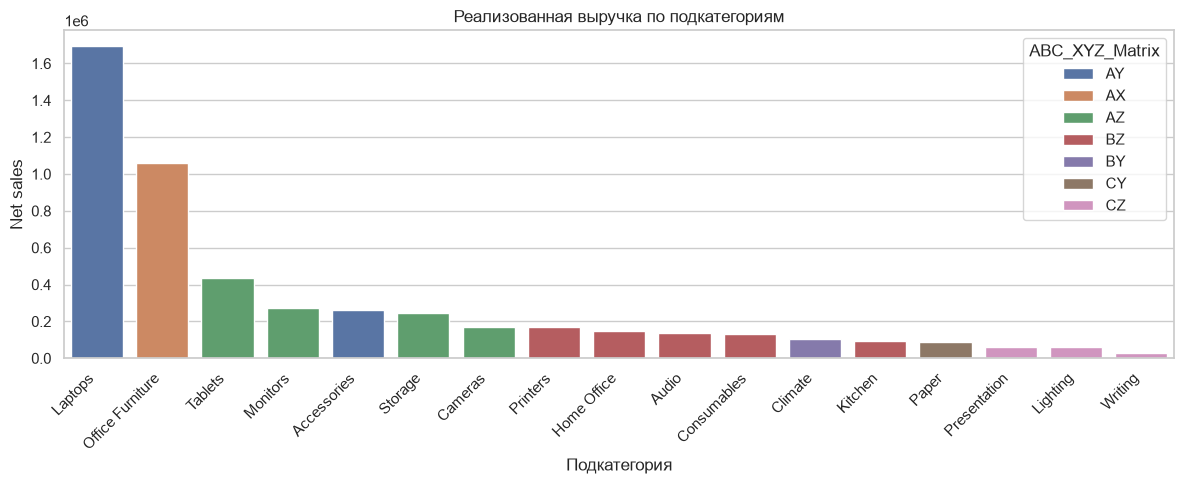

In [16]:
def plot_matrix(frame, title, ax):
    matrix = (frame.loc[frame['ABC_Group'].isin(['A','B','C']) & frame['XYZ_Group'].isin(['X','Y','Z'])]
              .groupby(['ABC_Group','XYZ_Group']).size().unstack(fill_value=0)
              .reindex(index=['A','B','C'],columns=['X','Y','Z'],fill_value=0))
    sns.heatmap(matrix,annot=True,fmt='d',cmap='YlGnBu',ax=ax)
    ax.set_title(title); ax.set_xlabel('XYZ: CV спроса'); ax.set_ylabel('ABC: вклад в выручку')

fig, axes = plt.subplots(1,2,figsize=(14,5))
plot_matrix(abc_xyz_sub,'ABC/XYZ: подкатегории',axes[0])
plot_matrix(abc_xyz_sku,'ABC/XYZ: SKU',axes[1])
plt.tight_layout(); plt.show()

plt.figure(figsize=(12,5))
plot_data = abc_xyz_sub.dropna(subset=['net_sales']).sort_values('net_sales',ascending=False)
sns.barplot(data=plot_data,x='product_subcategory',y='net_sales',hue='ABC_XYZ_Matrix')
plt.title('Реализованная выручка по подкатегориям')
plt.xlabel('Подкатегория'); plt.ylabel('Net sales'); plt.xticks(rotation=45,ha='right')
plt.tight_layout(); plt.show()


### Интерпретация ABC/XYZ

Группа X означает меньшую вариативность в наблюдаемом окне, Z — большую. Она не доказывает стабильность будущего спроса и не учитывает stockout, сезонные паттерны и изменения ассортимента. Рекомендации по запасам требуют дополнительно lead time, stock level, service level и данных о дефиците.

## Этап 7. RFM × ABC: профиль клиентов

In [17]:
customer_abc = calculate_abc(rfm.rename(columns={'monetary':'net_sales'}),'customer_id',value_col='net_sales')
customer_abc = customer_abc[['customer_id','ABC_Group','net_sales']].rename(columns={'ABC_Group':'cust_ABC','net_sales':'customer_net_sales'})
rfm_with_abc = rfm.merge(customer_abc,on='customer_id',how='left',validate='1:1')
rfm_with_abc['cust_ABC'] = rfm_with_abc['cust_ABC'].fillna('N/A')

profile = (rfm_with_abc.groupby(['segment','cust_ABC'],observed=True)
           .agg(clients=('customer_id','nunique'),avg_recency=('recency','mean'),
                avg_frequency=('frequency','mean'),total_revenue=('customer_net_sales','sum'))
           .round(2))
print(profile.to_string())

segment_summary = (rfm_with_abc.groupby('segment',observed=True)
                   .agg(clients=('customer_id','nunique'),median_recency=('recency','median'),
                        avg_frequency=('frequency','mean'),total_net_sales=('monetary','sum'))
                   .sort_values('total_net_sales',ascending=False))
print('\nRFM segment summary:')
print(segment_summary.round(2).to_string())


                       clients  avg_recency  avg_frequency  total_revenue
segment      cust_ABC                                                    
At Risk      B             207       743.99           2.61      122288.01
             C             220       762.90           2.22       50349.92
Big Spenders A              27       348.93           1.00       58561.11
             B               6       315.83           1.00        5697.03
Champions    A             715        97.40           5.32     2202615.80
             B              57       102.67           4.26       55227.24
Hibernating  B             196       946.79           1.00      116724.93
             C             670       952.18           1.00       85428.19
Lost VIPs    A             332       760.98           2.76      789875.46
             B              74       812.46           2.15       71201.70
Loyal        A             406       297.50           3.54     1034126.94
             B             509       1

## Этап 8. Бизнес-интерпретация и ограничения

Не называйте клиентов «ушедшими» только по одному RFM-сегменту: Recency зависит от даты среза и длины наблюдения. `Big Spenders` — крупные по Monetary и низкие по Frequency, но это не обязательно потерянные клиенты. Для вывода об оттоке нужны когортный retention/churn-анализ и бизнес-порог давности.

In [10]:
# Автоматически формируем проверяемые наблюдения вместо заранее заданных чисел.
print('Проверяемые наблюдения:')
if not yearly.empty:
    first_year, last_year = yearly.index.min(), yearly.index.max()
    if first_year != last_year:
        first_avg, last_avg = yearly.loc[first_year,'avg_monthly_sales'], yearly.loc[last_year,'avg_monthly_sales']
        print(f'Средняя месячная net sales: {first_year}={first_avg:,.2f}; {last_year}={last_avg:,.2f}.')
        print('Сравнение требует учитывать полноту календарных лет и изменение состава ассортимента.')

if not segment_summary.empty:
    top_segment = segment_summary['total_net_sales'].idxmax()
    print(f'Наибольшая суммарная Monetary в RFM-сегменте: {top_segment}.')

print('Ограничения: нет себестоимости логистики/обслуживания, остатков и stockout, дат доступности SKU.')
print('Не делать причинных выводов о сезонности, churn, B2B-эффективности или оптимальном запасе без дополнительных данных.')


Проверяемые наблюдения:
Средняя месячная net sales: 2022=105,126.77; 2025=122,807.22.
Сравнение требует учитывать полноту календарных лет и изменение состава ассортимента.
Наибольшая суммарная Monetary в RFM-сегменте: Champions.
Ограничения: нет себестоимости логистики/обслуживания, остатков и stockout, дат доступности SKU.
Не делать причинных выводов о сезонности, churn, B2B-эффективности или оптимальном запасе без дополнительных данных.


## Этап 9. Сохранение артефактов и паспорта анализа

In [11]:
artifacts = {
    'abc_xyz_sku.csv': abc_xyz_sku,
    'abc_xyz_subcategory.csv': abc_xyz_sub,
    'abc_xyz_category.csv': abc_xyz_cat,
    'rfm_with_abc.csv': rfm_with_abc,
    'monthly_sales.csv': monthly,
    'channel_summary.csv': channel_summary,
    'rfm_segment_summary.csv': segment_summary.reset_index(),
}
for name, frame in artifacts.items():
    frame.to_csv(EDA_DIR / name,index=False,encoding='utf-8-sig')

metadata = {
    'source_sales_file': 'processed/sales_bi_ready.csv',
    'transactions': int(len(df)),
    'customers': int(df['customer_id'].nunique()),
    'date_range': [str(df['order_date'].min().date()),str(df['order_date'].max().date())],
    'revenue_basis': 'Sales_Amount is recorded net sales per dictionary; realized subset uses analyst assumption Completed and Return_Flag != Yes',
    'profit_basis': 'Profit is recorded transaction profit per dictionary; no recomputation from Sales_Amount - Cost_Amount',
    'dictionary_file': 'sales_data_dictionary.csv',
    'abc_thresholds': {'A':0.80,'B':0.95},
    'xyz': {'metric':'monthly realized quantity','cv_ddof':0,'x_max':0.30,'y_max':0.40,'min_periods':6,
            'window':'first realized sale per item through dataset end; availability dates unavailable'},
    'rfm': {'basis':'realized purchases only','frequency':'unique composite key (customer_id, order_id)','monetary':'sum net_sales',
            'reference_date':str((df.loc[df.is_realized.eq(1),'order_date'].max().normalize()+pd.Timedelta(days=1)).date())},
    'limitations':['Dictionary does not specify official revenue-recognition timing','No SKU availability/stockout history','No customer service/fulfilment cost','Order_ID is reused across customers; analyses use customer_id + order_id composite key']
}
(EDA_DIR/'analysis_metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')

# QA: joins preserve entity counts and outputs are finite where expected.
assert abc_xyz_sku['product_id'].is_unique
assert abc_xyz_sub['product_subcategory'].is_unique
assert abc_xyz_cat['product_category'].is_unique
assert rfm_with_abc['customer_id'].is_unique
assert len(rfm_with_abc) == len(rfm)
print('Сохранены артефакты в:', EDA_DIR)
for name in artifacts:
    print(' -',name)
print('QA checks passed.')


Сохранены артефакты в: /Users/caseynger/DE/final_work_fa/eda
 - abc_xyz_sku.csv
 - abc_xyz_subcategory.csv
 - abc_xyz_category.csv
 - rfm_with_abc.csv
 - monthly_sales.csv
 - channel_summary.csv
 - rfm_segment_summary.csv
QA checks passed.
